**PROJECT 2: Customer Segmentation & Prediction**





In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


df = pd.read_csv("/content/data.csv", encoding='ISO-8859-1')

# Check first few rows
print(df.head())


  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER       6.0   
1    536365     71053                  WHITE METAL LANTERN       6.0   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER       8.0   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE       6.0   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.       6.0   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  


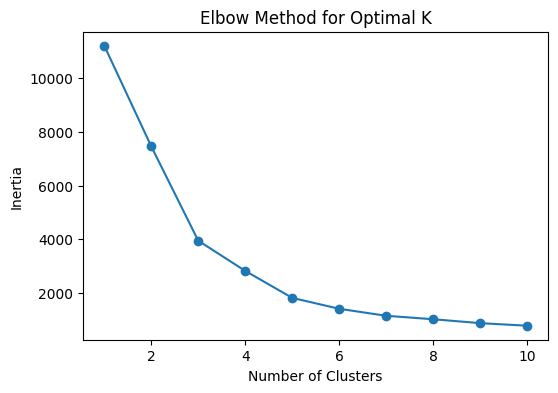

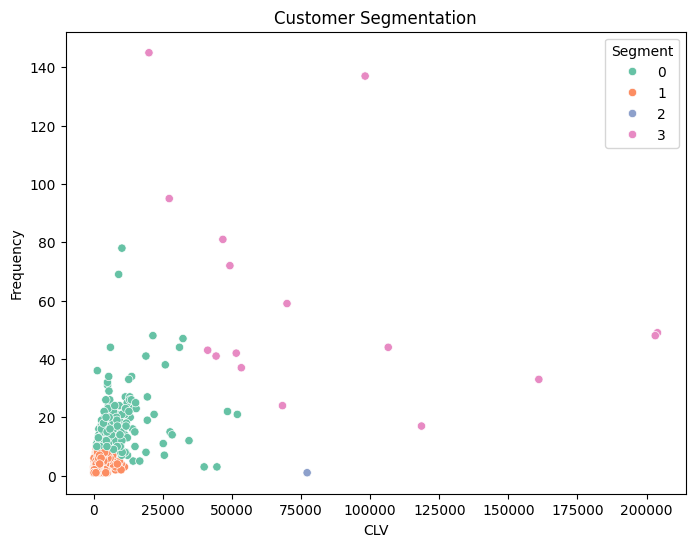

RMSE: 308.45
R2 Score: 0.99

Average Customer Lifetime Value per Segment:
Segment
0     7411.293370
1      885.204695
2    77183.600000
3    85190.284375
Name: CLV, dtype: float64

Segment 2:
High-value customers → Recommend loyalty programs and premium offers.

Segment 1:
Low-value customers → Recommend discounts, targeted promotions, and engagement campaigns.

Segment 3:
High-value customers → Recommend loyalty programs and premium offers.

Segment 0:
High-value customers → Recommend loyalty programs and premium offers.


In [30]:

# 1. Data Cleaning


# Drop duplicates
df.drop_duplicates(inplace=True)

# Drop rows with missing CustomerID
df = df.dropna(subset=['CustomerID'])

# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')

# Ensure numeric columns
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['UnitPrice'] = pd.to_numeric(df['UnitPrice'], errors='coerce')

# Remove rows with negative quantity or price (returns)
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]


# 2.Feature Engineering

# Total amount per transaction
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

# Customer Lifetime Value (CLV)
clv = df.groupby('CustomerID')['TotalAmount'].sum().reset_index()
clv.rename(columns={'TotalAmount': 'CLV'}, inplace=True)

# Average Order Value (AOV)
aov = df.groupby('CustomerID')['TotalAmount'].mean().reset_index()
aov.rename(columns={'TotalAmount': 'AOV'}, inplace=True)

# Frequency of Purchase
frequency = df.groupby('CustomerID')['InvoiceNo'].nunique().reset_index()
frequency.rename(columns={'InvoiceNo': 'Frequency'}, inplace=True)

# Merge features
customer_features = clv.merge(aov, on='CustomerID').merge(frequency, on='CustomerID')


# 3. Customer Segmentation (K-Means)


# Standardize features
scaler = StandardScaler()
X = scaler.fit_transform(customer_features[['CLV', 'AOV', 'Frequency']])

# Determine optimal clusters using Elbow method
inertia = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(6,4))
plt.plot(range(1,11), inertia, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.show()

# Fit K-Means with 4 clusters (example)
kmeans = KMeans(n_clusters=4, random_state=42)
customer_features['Segment'] = kmeans.fit_predict(X)

# Visualize Segments
plt.figure(figsize=(8,6))
sns.scatterplot(x='CLV', y='Frequency', hue='Segment', data=customer_features, palette='Set2')
plt.title('Customer Segmentation')
plt.show()


# 4. Predictive Modeling
# Predict future TotalAmount based on CLV, AOV, Frequency


# Target variable: TotalAmount in next purchase (simulated for demo)
customer_features['NextPurchaseAmount'] = customer_features['AOV'] * np.random.uniform(0.8,1.2, size=len(customer_features))

# Features & target
X_model = customer_features[['CLV','AOV','Frequency']]
y_model = customer_features['NextPurchaseAmount']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X_model, y_model, test_size=0.2, random_state=42)

# Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# -------------------------------
# 5. Evaluation
# -------------------------------
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"RMSE: {rmse:.2f}")
print(f"R2 Score: {r2:.2f}")

# -------------------------------
# 6. Insights
# -------------------------------

# Average CLV per segment
avg_clv_segment = customer_features.groupby('Segment')['CLV'].mean()
print("\nAverage Customer Lifetime Value per Segment:")
print(avg_clv_segment)

# Recommendations
for seg in customer_features['Segment'].unique():
    print(f"\nSegment {seg}:")
    if avg_clv_segment[seg] > customer_features['CLV'].mean():
        print("High-value customers → Recommend loyalty programs and premium offers.")
    else:
        print("Low-value customers → Recommend discounts, targeted promotions, and engagement campaigns.")
